# Customer Churn Prediction — Portfolio Version

**Project goal:** analyze telecom customer churn, train and compare classification models, evaluate the errors that matter to the business, and identify customer characteristics associated with churn.

**Dataset:** IBM Telco Customer Churn (`WA_Fn-UseC_-Telco-Customer-Churn.csv`).


## Workflow
1. Load and inspect the data
2. Explore churn patterns
3. Clean the data
4. Split into training and test sets
5. Preprocess features correctly
6. Train and compare three models
7. Evaluate the best model
8. Inspect feature importance
9. Save the model and test predictions

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay
)
import joblib

sns.set_theme(style="whitegrid")

## 1. Load the dataset


In [2]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Inspect the data



In [3]:
print("Column types:")
display(df.dtypes.to_frame("data_type"))

print("Missing values by column:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_values"))

print("Duplicate rows:", df.duplicated().sum())
print("\nChurn counts:")
display(df["Churn"].value_counts())
print("\nChurn proportions:")
display((df["Churn"].value_counts(normalize=True) * 100).round(1))

Column types:


,data_type
customerID,str
gender,str
SeniorCitizen,int64
Partner,str
Dependents,str
tenure,int64
PhoneService,str
MultipleLines,str
InternetService,str
OnlineSecurity,str


Missing values by column:


,missing_values
customerID,0
DeviceProtection,0
TotalCharges,0
MonthlyCharges,0
PaymentMethod,0
PaperlessBilling,0
Contract,0
StreamingMovies,0
StreamingTV,0
TechSupport,0


Duplicate rows: 0

Churn counts:


Churn
No     5174
Yes    1869
Name: count, dtype: int64


Churn proportions:


Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64

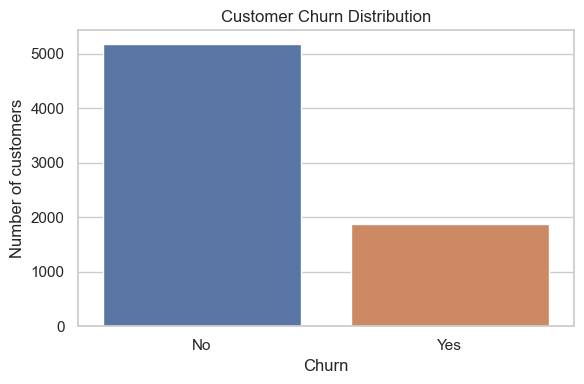

In [4]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn", hue="Churn", legend=False)
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

## 3. Explore possible churn patterns



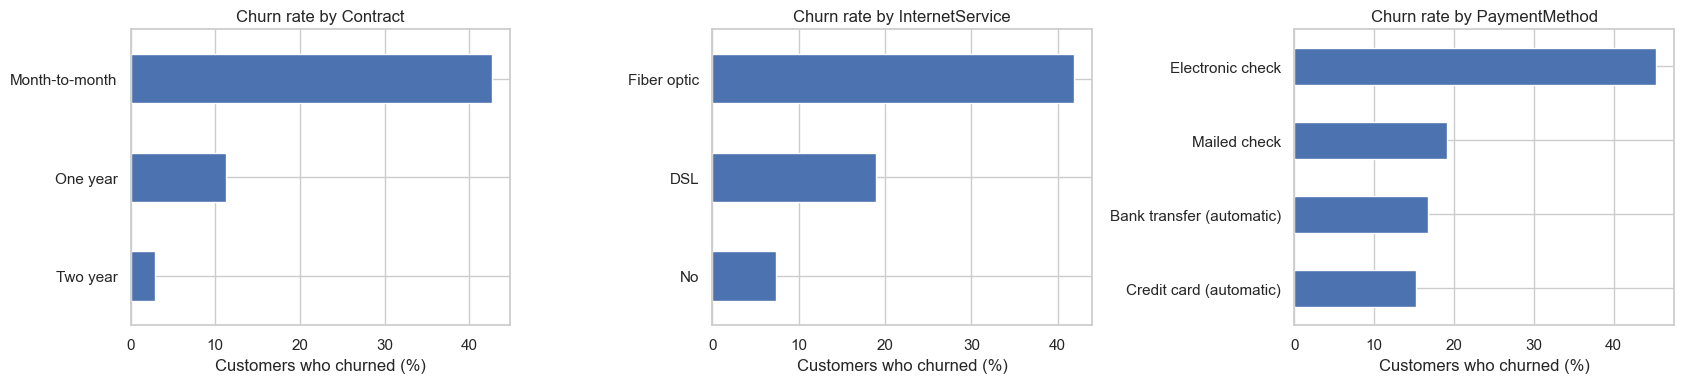

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

for ax, col in zip(axes, ["Contract", "InternetService", "PaymentMethod"]):
    churn_rate = df.groupby(col, observed=False)["Churn"].apply(
        lambda values: (values == "Yes").mean() * 100
    ).sort_values()
    churn_rate.plot(kind="barh", ax=ax)
    ax.set_title(f"Churn rate by {col}")
    ax.set_xlabel("Customers who churned (%)")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

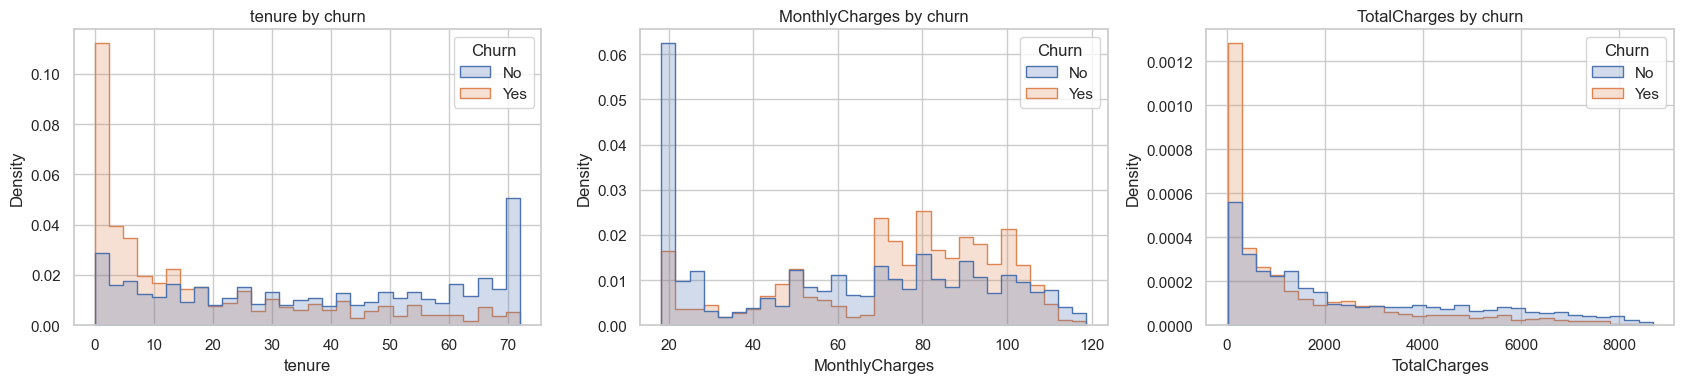

In [6]:
df_plot = df.copy()
df_plot["TotalCharges"] = pd.to_numeric(df_plot["TotalCharges"], errors="coerce")

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.histplot(data=df_plot, x=col, hue="Churn", bins=30, element="step",
                 stat="density", common_norm=False, ax=ax)
    ax.set_title(f"{col} by churn")
plt.tight_layout()
plt.show()

## 4. Clean and prepare the target

- `customerID` is an identifier, so we exclude it from the predictors.
- `TotalCharges` is stored as text in this dataset; convert it to a numeric column.
- Blank values become missing values. We will fill missing numeric/categorical values inside the preprocessing pipeline, using training data only.
- The target `Churn` becomes `1` for Yes and `0` for No.

In [7]:
data = df.drop(columns=["customerID"]).copy()

data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce")
data["Churn"] = data["Churn"].map({"No": 0, "Yes": 1})

print("Target values:")
print(data["Churn"].value_counts())
print("\nRows:", len(data))
print("Missing TotalCharges:", data["TotalCharges"].isna().sum())

Target values:
Churn
0    5174
1    1869
Name: count, dtype: int64

Rows: 7043
Missing TotalCharges: 11


## 5. Separate features and target, then split

- `X` = information used to predict churn.
- `y` = the answer the model learns to predict.
- The test set is kept aside until evaluation.



In [8]:
X = data.drop(columns=["Churn"])
y = data["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training customers:", len(X_train))
print("Testing customers:", len(X_test))
print("Churn rate in training set:", round(y_train.mean() * 100, 1), "%")
print("Churn rate in test set:", round(y_test.mean() * 100, 1), "%")

Training customers: 5634
Testing customers: 1409
Churn rate in training set: 26.5 %
Churn rate in test set: 26.5 %


## 6. Preprocess numeric and categorical columns

Machine learning models need numeric inputs.

- Numeric columns: fill missing values with the median and standardize their scales.
- Categorical columns: fill missing values with the most common category, then one-hot encode them into 0/1 columns.

A `Pipeline` keeps preprocessing and model training together. Each model learns preprocessing from the training data only, then applies the same transformations to test data.

In [10]:
# Separate numerical and categorical columns
numeric_features = X_train.select_dtypes(include="number").columns
categorical_features = X_train.select_dtypes(exclude="number").columns


numeric_preprocessing = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessing = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_preprocessing, numeric_features),
    ("cat", categorical_preprocessing, categorical_features)
])

## 7. Train and compare three models

We compare different approaches:
- **Logistic Regression:** a useful baseline and relatively easy to interpret.
- **Random Forest:** combines many decision trees.
- **Gradient Boosting:** builds trees sequentially, with later trees trying to correct earlier errors.



In [11]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=12, min_samples_leaf=3,
        class_weight="balanced", random_state=42, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100, learning_rate=0.05, max_depth=2, random_state=42
    )
}

trained_models = {}
results = []
test_probabilities = {}

for name, classifier in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessing", preprocessor),
        ("model", classifier)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    trained_models[name] = pipeline
    test_probabilities[name] = probabilities

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results).sort_values("ROC-AUC", ascending=False)
display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
2,Gradient Boosting,0.799,0.663,0.495,0.567,0.844
0,Logistic Regression,0.738,0.504,0.783,0.614,0.841
1,Random Forest,0.766,0.546,0.701,0.614,0.840


## 8. Compare model performance visually

These charts make it easier to compare models. The ROC curve shows the trade-off between detecting churners and incorrectly flagging customers who would stay. A curve closer to the top-left is generally better; ROC-AUC summarizes this ranking performance.

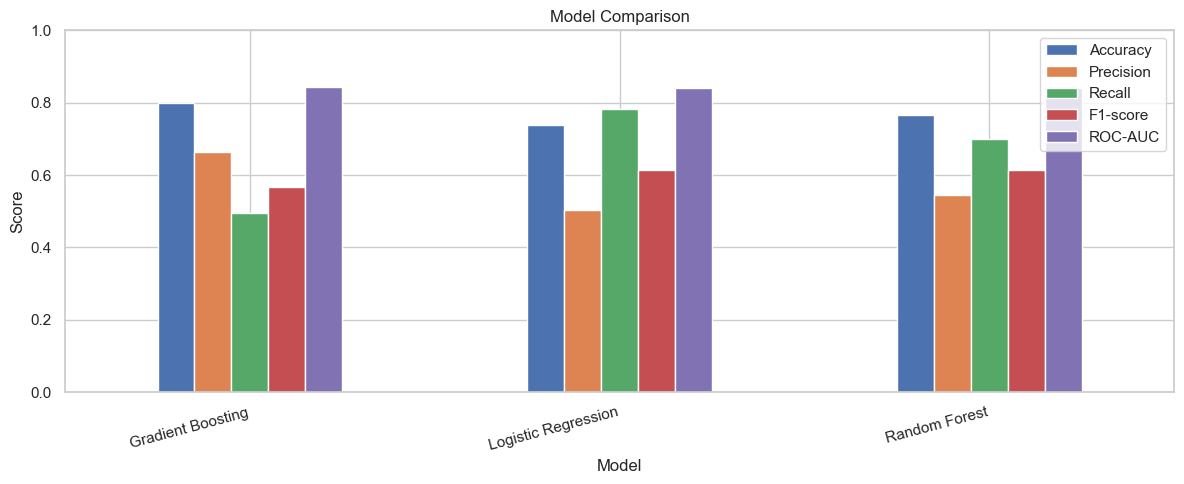

In [12]:
metrics_to_plot = results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]]
metrics_to_plot.plot(kind="bar", figsize=(12, 5), ylim=(0, 1))
plt.title("Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

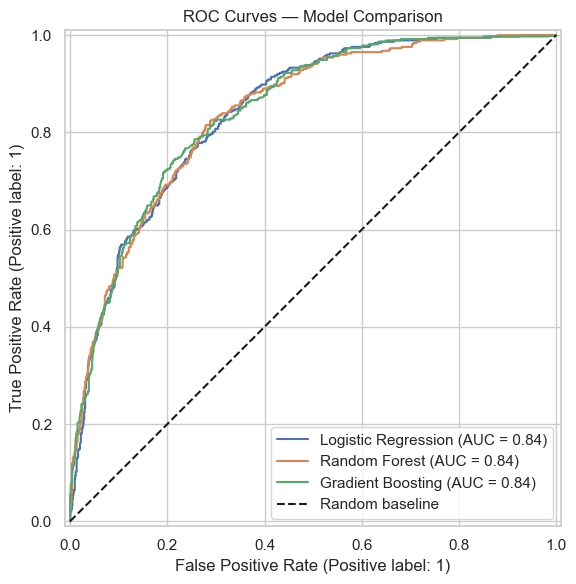

In [13]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, probabilities in test_probabilities.items():
    RocCurveDisplay.from_predictions(y_test, probabilities, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random baseline")
ax.set_title("ROC Curves — Model Comparison")
ax.legend()
plt.tight_layout()
plt.show()

## 9. Evaluate the best model



In [15]:
best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]
best_predictions = best_model.predict(X_test)
best_probabilities = best_model.predict_proba(X_test)[:, 1]

print("Selected model:", best_name)
print("\nClassification report:")
print(classification_report(
    y_test, best_predictions,
    target_names=["Stayed", "Churned"],
    zero_division=0
))

Selected model: Gradient Boosting

Classification report:
              precision    recall  f1-score   support

      Stayed       0.83      0.91      0.87      1035
     Churned       0.66      0.49      0.57       374

    accuracy                           0.80      1409
   macro avg       0.75      0.70      0.72      1409
weighted avg       0.79      0.80      0.79      1409



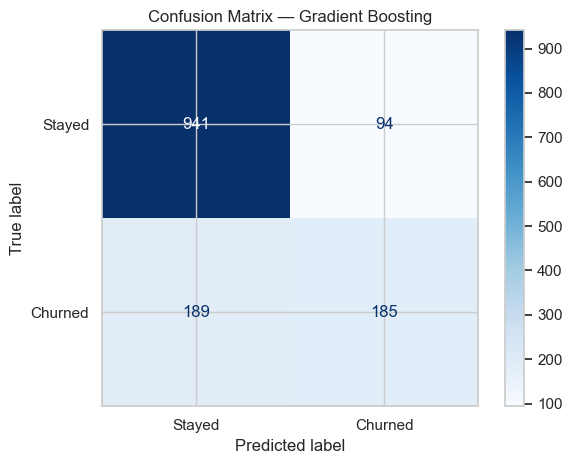

True negatives (correctly predicted stayed): 941
False positives (flagged but stayed): 94
False negatives (missed churners): 189
True positives (correctly detected churners): 185


In [16]:
ConfusionMatrixDisplay.from_predictions(
    y_test, best_predictions,
    display_labels=["Stayed", "Churned"],
    cmap="Blues"
)
plt.title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, best_predictions).ravel()
print("True negatives (correctly predicted stayed):", tn)
print("False positives (flagged but stayed):", fp)
print("False negatives (missed churners):", fn)
print("True positives (correctly detected churners):", tp)

## 10. Understand important features

For tree-based models, feature importance estimates how much each encoded feature contributes to reducing errors across the trees. It can help guide further investigation, but it does **not** prove causation and is not the same as a business explanation.


,Feature,Importance
36,cat__Contract_Month-to-month,0.371897
1,num__tenure,0.173539
16,cat__InternetService_Fiber optic,0.128748
18,cat__OnlineSecurity_No,0.085244
27,cat__TechSupport_No,0.060842
43,cat__PaymentMethod_Electronic check,0.060116
3,num__TotalCharges,0.036276
2,num__MonthlyCharges,0.029772
38,cat__Contract_Two year,0.010293
40,cat__PaperlessBilling_Yes,0.008769


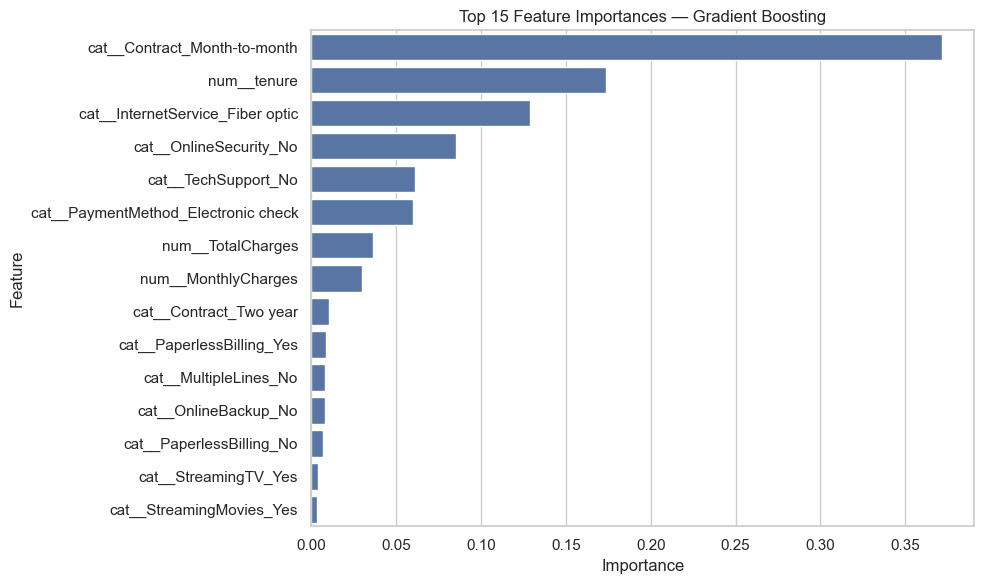

In [18]:
if best_name in ["Random Forest", "Gradient Boosting"]:
    fitted_preprocessor = best_model.named_steps["preprocessing"]
    fitted_classifier = best_model.named_steps["model"]

    feature_names = fitted_preprocessor.get_feature_names_out()
    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": fitted_classifier.feature_importances_
    }).sort_values("Importance", ascending=False).head(15)

    display(importance_df)

    plt.figure(figsize=(10, 6))
    sns.barplot(data=importance_df, x="Importance", y="Feature")
    plt.title(f"Top 15 Feature Importances — {best_name}")
    plt.tight_layout()
    plt.show()
else:
    print("The selected Logistic Regression model does not provide tree feature_importances_.")
    print("You can inspect its coefficients in a later extension.")

## 11. Export predictions and save the trained pipeline

`joblib` saves a Python object to a file so it can be loaded later without training again. We save the **entire pipeline**, including preprocessing and the model, so future data receives the same transformations.

The output files are written to the current notebook folder.

In [19]:
prediction_output = X_test.copy()
prediction_output["ActualChurn"] = y_test
prediction_output["ChurnProbability"] = best_probabilities
prediction_output["PredictedChurn"] = best_predictions
prediction_output["RiskSegment"] = pd.cut(
    best_probabilities,
    bins=[-0.001, 0.30, 0.60, 1.001],
    labels=["Low", "Medium", "High"]
)

prediction_output.to_csv("churn_test_predictions.csv", index=False)
joblib.dump(best_model, "churn_prediction_pipeline.joblib")

print("Saved: churn_test_predictions.csv")
print("Saved: churn_prediction_pipeline.joblib")
print("Best model selected:", best_name)

Saved: churn_test_predictions.csv
Saved: churn_prediction_pipeline.joblib
Best model selected: Gradient Boosting


## 12. Example: predict one customer's churn risk

Use one customer from the test set as an example. The probability is the model's estimated churn probability, not a guarantee of what will happen.

In [20]:
one_customer = X_test.iloc[[0]]
churn_probability = best_model.predict_proba(one_customer)[0, 1]
churn_prediction = best_model.predict(one_customer)[0]

print("Estimated churn probability:", f"{churn_probability:.1%}")
print("Predicted outcome:", "Churn" if churn_prediction == 1 else "No churn")
print("Actual outcome:", "Churn" if y_test.iloc[0] == 1 else "No churn")

Estimated churn probability: 6.1%
Predicted outcome: No churn
Actual outcome: No churn


## Final summary

This project demonstrates:
- Exploratory data analysis and visual storytelling
- Data cleaning and categorical encoding
- A train/test split that preserves the target balance
- A preprocessing pipeline to reduce data leakage
- Comparison of three classification algorithms
- Evaluation using precision, recall, F1-score, ROC-AUC, and a confusion matrix
- Feature-importance analysis
- Exporting predictions and saving a reusable model pipeline

